In [1]:
import pandas as pd
import numpy as np
import pathlib
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, spearmanr
import python_anesthesia_simulator as pas
from stimuli_effect_identification import dataset_simulation

/home/baubouin/Code/stimuli_effect_identification/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load data
data_measure = pd.read_csv('data/database.csv')
if "opstart" in data_measure.columns:
    data_measure.rename(columns={'opstart': 'surgery_time'}, inplace=True)
data_measure['Propofol'] = data_measure['Propofol']*20/3600  # convert in mg/s
data_measure['Remifentanil'] = data_measure['Remifentanil']*20/3600  # convert in µg/s
data_measure.intubation_time = (data_measure.intubation_time - 2*60).clip(0, 600)  # from end to start of intubation
data_measure['TPR'] = (data_measure['MAP'] / (data_measure['HR'] * data_measure['SV'])).clip(0, 0.04)

In [3]:
if pathlib.Path("data/simulated_vitaldb_no_stimuli.csv").exists():
    data_simu = pd.read_csv("data/simulated_vitaldb_no_stimuli.csv")
else:
    data_simu = dataset_simulation(
        data_measure,
        bar=True,
        dist_profil=None,
    )
    data_simu.to_csv('data/simulated_vitaldb_no_stimuli.csv')
    

In [4]:
data_simu = data_simu.add_suffix('_sim', )
data_simu = data_simu.rename(index=str, columns={'Time_sim':'Time', 'caseid_sim':'caseid'})
data = pd.merge(data_simu, data_measure, on=['caseid', 'Time'])

In [5]:
data.columns

Index(['Unnamed: 0_sim', 'Time', 'BIS_sim', 'LOC_sim', 'TOL_sim', 'TOF_sim',
       'TPR_sim', 'SV_sim', 'HR_sim', 'MAP_sim', 'CO_sim', 'DAP_sim',
       'SAP_sim', 'u_propo_sim', 'u_remi_sim', 'u_nore_sim', 'u_atra_sim',
       'x_propo_1_sim', 'x_propo_2_sim', 'x_propo_3_sim', 'x_propo_4_sim',
       'x_remi_1_sim', 'x_remi_2_sim', 'x_remi_3_sim', 'x_remi_4_sim',
       'x_atra_1_sim', 'x_atra_2_sim', 'x_atra_3_sim', 'x_atra_4_sim',
       'x_nore_1_sim', 'caseid', 'Unnamed: 0', 'BIS', 'SQI', 'Propofol',
       'Remifentanil', 'MAP', 'SAP', 'DAP', 'NI_MAP', 'NI_SAP', 'NI_DAP', 'HR',
       'Vol_Rem', 'Vol_Prop', 'Ce_Remi', 'Ce_Prop', 'Cp_Remi', 'Cp_Prop', 'RR',
       'SV', 'age', 'sex', 'weight', 'height', 'bmi', 'surgery_time',
       'intubation_time', 'approach', 'bis_base', 'hr_base', 'map_base',
       'sv_base', 'TPR'],
      dtype='object')

# Compare before and after start of operation

To account for variability in surgery_time definition, we are comparing the mean value during 10 minute before start of operation to the start and mean value during the 10 minute after start of operation.

In [6]:
signal_list = ['BIS', 'MAP', 'HR', 'SV']
list_of_df = []
max_period = 10 # include max_period minute before and after
min_period = 5 # exclude min_period minute before and after
for caseid, data_case in data.groupby('caseid'):
    data_case.reset_index(inplace=True)

    # surgery_time values
    surgery_time = int(data_case['surgery_time'].iloc[0])
    # if surgery_time>60*60:
    #     print(f"case {caseid} surgery_time too long")
    #     continue
    data_before = data_case.iloc[surgery_time - max_period*60: surgery_time-min_period*60]
    data_after = data_case.iloc[surgery_time+min_period*60: surgery_time + max_period*60]
    data_during = data_case.iloc[surgery_time-min_period*60: surgery_time + min_period*60]
    line = data_case.loc[0,['caseid', 'age', 'weight', 'height', 'bmi', 'sex', 'approach']]
    line = pd.DataFrame(line).transpose()
    for signal in signal_list:
        line.insert(0, f"{signal}_diff_before", data_before[signal].median() - data_before[f"{signal}_sim"].median())
        line.insert(0, f"{signal}_diff_after", data_after[signal].median() - data_after[f"{signal}_sim"].median())
        line.insert(0, f"{signal}_diff_max_before", data_before[signal].max() - data_before[f"{signal}_sim"].max())
        line.insert(0, f"{signal}_diff_max_after", data_after[signal].max() - data_after[f"{signal}_sim"].max())
        line.insert(0, f"{signal}_diff_max_during", data_during[signal].max() - data_during[f"{signal}_sim"].max())
    line.insert(0, 'remi_ce_opstart', data_case['Ce_Remi'].iloc[surgery_time])
    line.insert(0, 'propo_ce_opstart', data_case['Ce_Prop'].iloc[surgery_time])

    # intubation values
    intubation_time = int(data_case['intubation_time'].iloc[0])
    data_during = data_case.iloc[intubation_time-min_period*60: intubation_time + min_period*60]
    for signal in signal_list:
        line.insert(0, f"{signal}_diff_max_during_intub", data_during[signal].max() - data_during[f"{signal}_sim"].max())
    line.insert(0, 'remi_ce_intub', data_case['Ce_Remi'].iloc[intubation_time])
    line.insert(0, 'propo_ce_intub', data_case['Ce_Prop'].iloc[intubation_time])
    line.insert(0, 'tol_intub', data_case['TOL_sim'].iloc[intubation_time])

    list_of_df.append(line)

result_df =  pd.concat(
    list_of_df,
    axis=0,
    ignore_index=True
)

result_df_intub = result_df.copy()
# result_df = result_df.query('approach=="Open"')

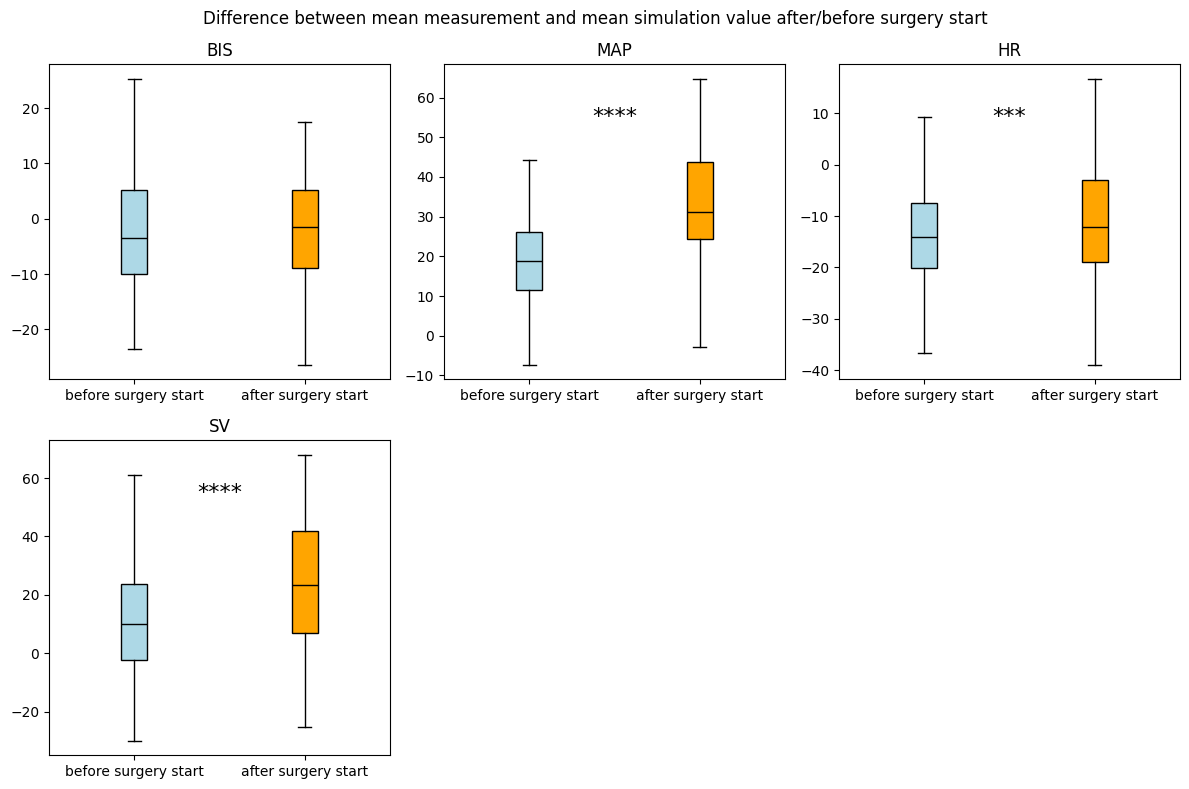

In [7]:
plt.figure(figsize=(12, 8))

for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)

    before = result_df[f'{signal}_diff_before']
    after = result_df[f'{signal}_diff_after']

    bplot = plt.boxplot([before, after], patch_artist=True, showfliers=False)
    for patch, color in zip(bplot['boxes'], ['lightblue', 'orange']):
        patch.set_facecolor(color)
    for median in bplot['medians']:
        median.set_color('black')

    plt.xticks([1, 2], labels=['before surgery start', 'after surgery start'])
    plt.title(signal)
    stat, p_two_tailed = ttest_rel(after, before, nan_policy='omit')  # note: after - before

    # One-tailed p-value: test if after > before
    if stat > 0:
        p_one_tailed = p_two_tailed / 2
    else:
        p_one_tailed = 1 - p_two_tailed / 2

    # Significance stars
    if p_one_tailed <= 0.0001:
        stars = '****'
    elif p_one_tailed <= 0.001:
        stars = '***'
    elif p_one_tailed <= 0.01:
        stars = '**'
    elif p_one_tailed <= 0.05:
        stars = '*'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.8 * (y_lim[1]-y_lim[0])
        plt.text(1.5, y_text, stars, ha='center', va='bottom', fontsize=16, color='black')
result_df
plt.suptitle("Difference between mean measurement and mean simulation value after/before surgery start")
plt.tight_layout()
plt.show()

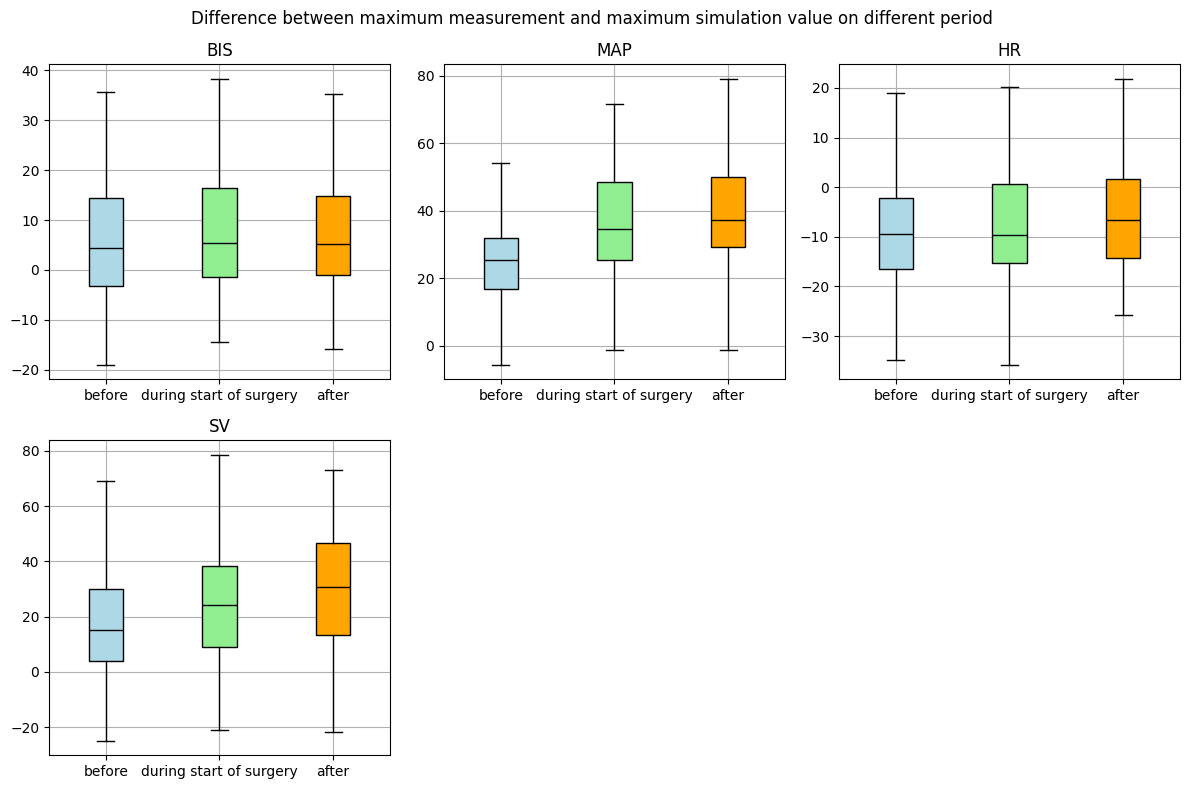

In [8]:
plt.figure(figsize=(12, 8))
result_df
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)

    before = result_df[f'{signal}_diff_max_before']
    during = result_df[f'{signal}_diff_max_during']
    after = result_df[f'{signal}_diff_max_after']

    bplot = plt.boxplot([before, during, after], patch_artist=True, showfliers=False)
    for patch, color in zip(bplot['boxes'], ['lightblue', 'lightgreen', 'orange']):
        patch.set_facecolor(color)
    for median in bplot['medians']:
        median.set_color('black')

    plt.xticks([1, 2, 3], labels=['before', 'during start of surgery', 'after'])
    plt.title(signal)
    plt.grid()

plt.suptitle("Difference between maximum measurement and maximum simulation value on different period ")
plt.tight_layout()
plt.show()

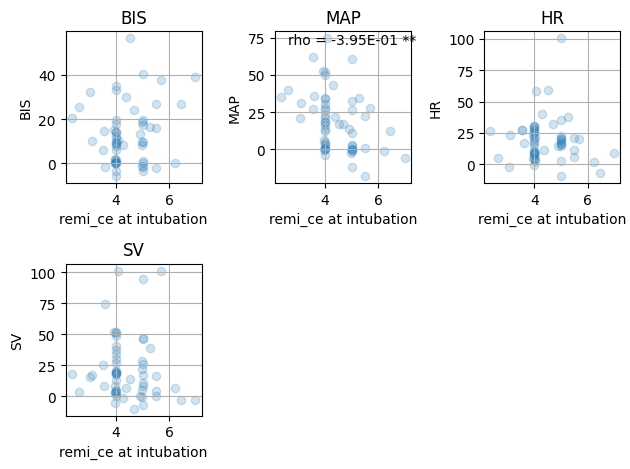

In [9]:
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)
    x = 'remi_ce' #remi_ce, propo_ce, tol
    plt.scatter(result_df_intub[f'{x}_intub'], result_df_intub[f"{signal}_diff_max_during_intub"], alpha = 0.2)
    before_test = result_df_intub[[f'{x}_intub', f"{signal}_diff_max_during_intub"]].dropna()
    plt.xlabel(f"{x} at intubation")
    plt.ylabel(f"{signal}")
    rho, p = spearmanr(before_test[f'{x}_intub'], before_test[f"{signal}_diff_max_during_intub"])
    # Significance stars
    if p <= 0.0001:
        stars = f'rho = {rho:.2E} ****'
    elif p <= 0.001:
        stars = f'rho = {rho:.2E} ***'
    elif p <= 0.01:
        stars = f'rho = {rho:.2E} **'
    elif p <= 0.05:
        stars = f'rho = {rho:.2E} *'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.9 * (y_lim[1]-y_lim[0])
        x_lim = plt.gca().get_xlim()
        x_text = x_lim[0] + 0.1 * (x_lim[1]-x_lim[0])
        plt.text(x_text, y_text, stars, ha='left', va='bottom', fontsize=10, color='black')

    plt.grid()
    plt.title(signal)

plt.tight_layout()
plt.show()

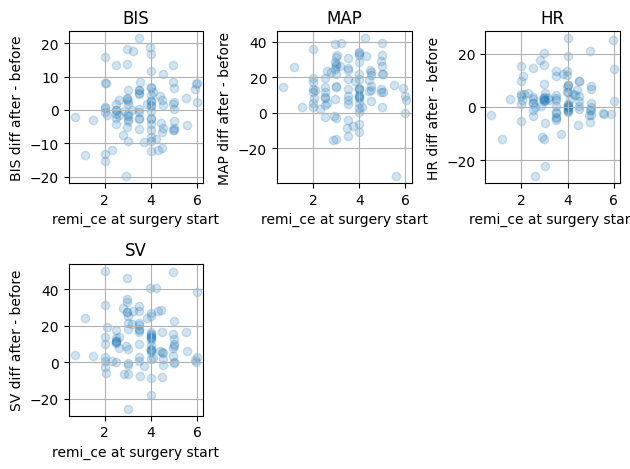

In [10]:
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)
    before = result_df[f'{signal}_diff_before']
    after = result_df[f'{signal}_diff_after']
    diff = after - before
    plt.scatter(result_df['remi_ce_opstart'], diff, alpha = 0.2)
    plt.xlabel("remi_ce at surgery start")
    plt.ylabel(f"{signal} diff after - before")

    rho, p = spearmanr(result_df['remi_ce_opstart'], diff)
    # Significance stars
    if p <= 0.0001:
        stars = f'rho = {rho:.2E} ****'
    elif p <= 0.001:
        stars = f'rho = {rho:.2E} ***'
    elif p <= 0.01:
        stars = f'rho = {rho:.2E} **'
    elif p <= 0.05:
        stars = f'rho = {rho:.2E} *'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.9 * (y_lim[1]-y_lim[0])
        plt.text(1.5, y_text, stars, ha='left', va='bottom', fontsize=10, color='black')

    plt.grid()
    plt.title(signal)

plt.tight_layout()
plt.show()

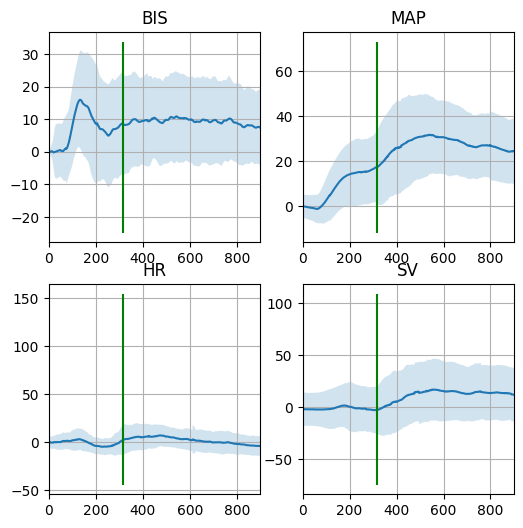

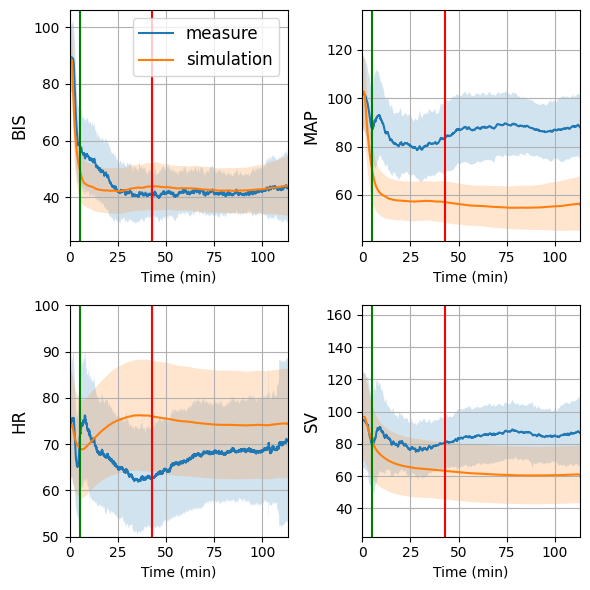

In [14]:
min_case_duration = data.groupby('caseid')['Time'].max().min()

data['Time'] = data.groupby('caseid')['Time'].transform(lambda x: x - x.min())
intub_median = np.median(data['intubation_time'].unique())
opstart_median = np.median(data['surgery_time'].unique())
plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    data[f"{signal}_diff"] = data[signal] - data[f"{signal}_sim"]
    y_diff_mean = data.groupby("Time")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data.groupby("Time")[f"{signal}_diff"].std().reset_index()
    y_measure = data.groupby("Time")[signal].mean().reset_index()
    y_sim = data.groupby("Time")[f"{signal}_sim"].mean().reset_index()
    x = y_diff_mean['Time'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    plt.grid()
    ylim = plt.gca().get_ylim()
    plt.vlines(intub_median, ylim[0], ylim[1], 'g')
    plt.vlines(opstart_median, ylim[0], ylim[1], 'r')
    plt.title(signal)
    plt.xlim(0, 15*60)
plt.show()



plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data.groupby("Time")[signal].mean().reset_index()
    y_measure_std = data.groupby("Time")[signal].std().reset_index()
    y_sim = data.groupby("Time")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data.groupby("Time")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label= 'measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label= 'simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    x = y_diff_mean['Time'].values/60
    plt.axvline(x=intub_median/60, color='g')
    plt.axvline(x=opstart_median/60, color='r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    plt.xlim(0, min_case_duration/60)
    if signal=='HR':
        plt.ylim(50,100)
    
    if i==0:
        plt.legend(fontsize=12)
    plt.xlabel('Time (min)')
plt.tight_layout()

if not pathlib.Path('output').exists():
    pathlib.Path('output').mkdir()

plt.savefig('output/all_signal_comparison.pdf', dpi=300)   
plt.show()

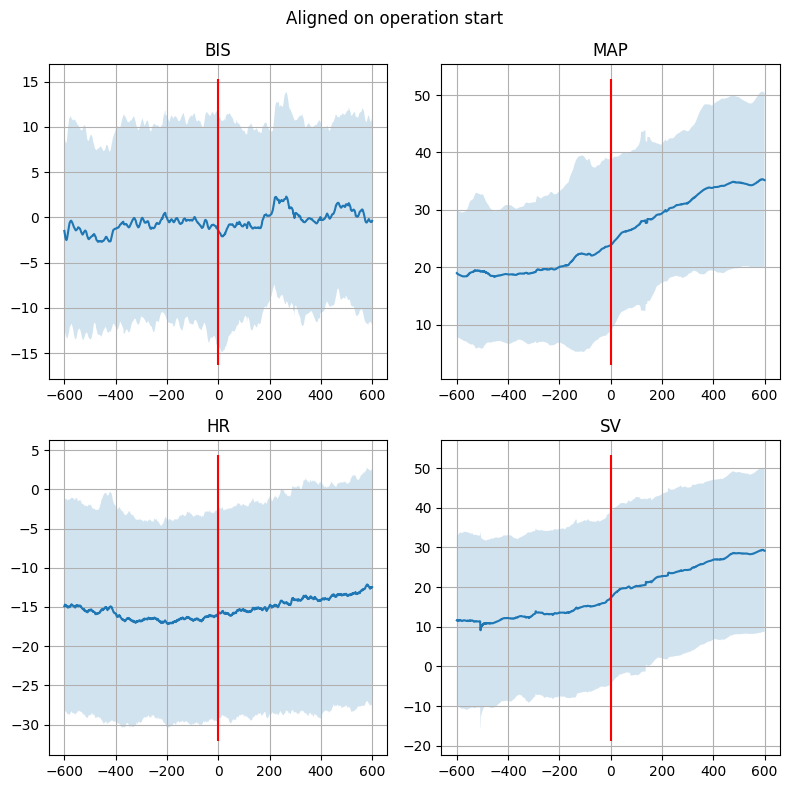

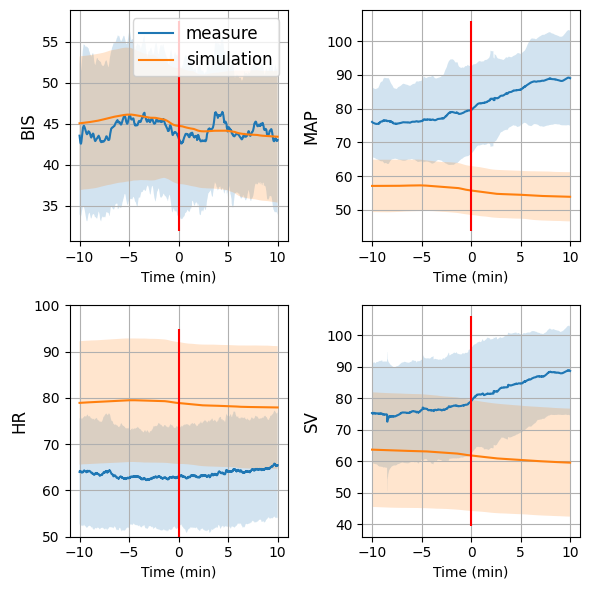

In [15]:
data['Time_aligned'] = data['Time'] - data['surgery_time']
data_opstart = data.query("(Time_aligned>= -10*60) & (Time_aligned <=10*60) & (approach=='Open')").copy()
plt.figure(figsize=(8,8))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    data_opstart[f"{signal}_diff"] = data_opstart[signal] - data_opstart[f"{signal}_sim"]
    y_diff_mean = data_opstart.groupby("Time_aligned")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data_opstart.groupby("Time_aligned")[f"{signal}_diff"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.title(signal)

plt.suptitle("Aligned on operation start")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_opstart.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_opstart.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_opstart.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_opstart.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    # plt.xlim(0, min_case_duration/60)
    if signal=='HR':
        plt.ylim(50,100)
    
    if i==0:
        plt.legend(fontsize=12)
    plt.xlabel('Time (min)')
plt.tight_layout()
plt.savefig('output/all_signal_opstart.pdf', dpi=300)   
plt.show()

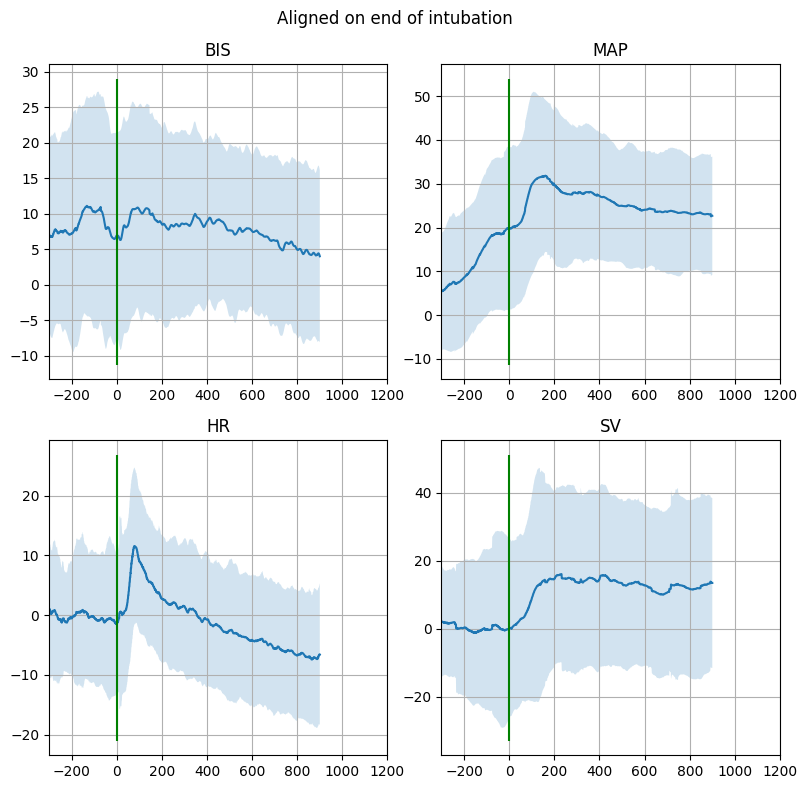

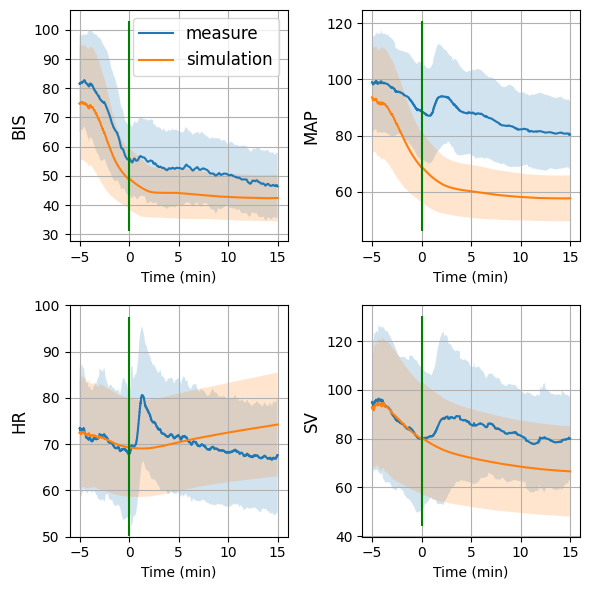

In [16]:
data['Time_aligned'] = data['Time'] - data['intubation_time']
data_intub = data.query("(Time_aligned>= -5*60) & (Time_aligned <=15*60)").copy()
plt.figure(figsize=(8,8))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    data_intub[f"{signal}_diff"] = data_intub[signal] - data_intub[f"{signal}_sim"]
    y_diff_mean = data_intub.groupby("Time_aligned")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data_intub.groupby("Time_aligned")[f"{signal}_diff"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.title(signal)
    plt.xlim(-5*60,20*60)
plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label = 'simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    
    if i==0:
        plt.legend(fontsize=12)
    plt.xlabel('Time (min)')
plt.tight_layout()
plt.savefig('output/all_signal_intub.pdf', dpi=300)   
plt.show()